# Experiment 11: Reinforcement Learning using Q-Learning (Grid World)
**Aim:** Train a Q-Learning agent on a 4×4 Grid World, compare exploration–exploitation strategies (ε-greedy) and find the optimal policy.

**Environment:** 4×4 grid, states 0–15. Start = 0 (top-left), Goal = 15 (bottom-right). Actions: Up, Down, Left, Right.
Reward: **+10** for reaching the goal, **−1** for every other step. Moving into a wall keeps the agent in the same cell.

**Q-Learning update:** Q(s,a) ← Q(s,a) + α [ r + γ · max Q(s',a') − Q(s,a) ]

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Environment

In [3]:
N = 4                      # 4x4 grid
START, GOAL = 0, 15
ACTIONS = ["Up", "Down", "Left", "Right"]
ARROWS = ["↑", "↓", "←", "→"]

def step(state, action):
    row, col = divmod(state, N)
    if action == 0: row -= 1      # Up
    if action == 1: row += 1      # Down
    if action == 2: col -= 1      # Left
    if action == 3: col += 1      # Right

    if row < 0 or row >= N or col < 0 or col >= N:   # hit the wall -> stay in place
        return state, -1, False

    next_state = row * N + col
    if next_state == GOAL:
        return next_state, 10, True
    return next_state, -1, False

## Q-Learning with ε-greedy (explore with probability ε, otherwise exploit the best known action)

In [4]:
def train(epsilon, episodes=500, alpha=0.1, gamma=0.9, max_steps=30):
    np.random.seed(42)
    Q = np.zeros((N * N, 4))
    rewards, success = [], []

    for ep in range(episodes):
        state, total, done = START, 0, False
        for t in range(max_steps):
            if np.random.rand() < epsilon:
                action = np.random.randint(4)          # explore: random action
            else:
                action = np.argmax(Q[state])           # exploit: best action

            next_state, reward, done = step(state, action)

            # Q-learning update rule
            target = reward if done else reward + gamma * np.max(Q[next_state])
            Q[state, action] += alpha * (target - Q[state, action])

            state = next_state
            total += reward
            if done:
                break
        rewards.append(total)
        success.append(done)
    return Q, rewards, success

## Compare exploration strategies (ε = 0.5, 0.1, 0.01)

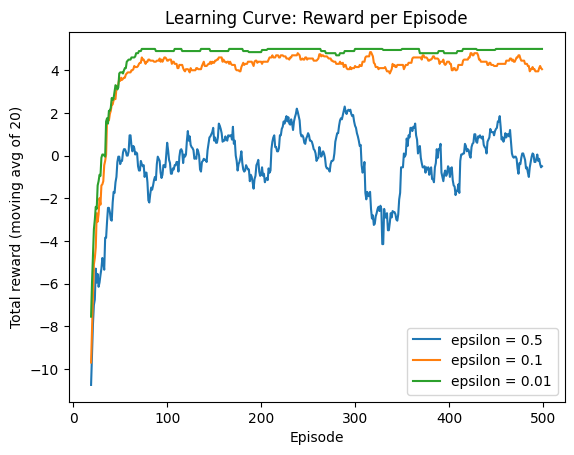

,Epsilon,Success Rate (%),Avg Reward,Avg Reward (last 100)
0,0.50,98.4,-0.61,0.19
1,0.10,99.0,3.69,4.34
2,0.01,99.4,4.31,4.99


In [5]:
agents = {}
rows = []
for eps in [0.5, 0.1, 0.01]:
    Q, rewards, success = train(eps)
    agents[eps] = Q
    rows.append([eps, np.mean(success) * 100, np.mean(rewards), np.mean(rewards[-100:])])

    plt.plot(pd.Series(rewards).rolling(20).mean(), label=f"epsilon = {eps}")

plt.xlabel("Episode")
plt.ylabel("Total reward (moving avg of 20)")
plt.title("Learning Curve: Reward per Episode")
plt.legend()
plt.show()

pd.DataFrame(rows, columns=["Epsilon", "Success Rate (%)", "Avg Reward", "Avg Reward (last 100)"]).round(2)

## Learned Q-table and optimal policy (ε = 0.1)

In [6]:
Q = agents[0.1]
pd.DataFrame(Q, columns=ACTIONS).round(2)

,Up,Down,Left,Right
0,-0.17,-0.81,-0.19,1.81
1,0.61,3.12,0.10,0.72
2,-0.75,3.47,-0.53,-0.83
3,-0.58,-0.35,-0.53,-0.49
4,-1.35,-1.14,-1.31,2.51
5,0.72,4.58,0.07,3.43
6,-0.57,6.16,0.45,-0.41
7,-0.30,1.87,-0.22,-0.21
8,-0.81,-0.75,-0.77,3.12
9,2.28,3.08,0.32,6.20


In [7]:
policy = [ARROWS[np.argmax(Q[s])] for s in range(N * N)]
policy[GOAL] = "G"
print("Optimal Policy:")
print(np.array(policy).reshape(N, N))

# follow the policy from start to goal
state, path = START, [START]
while state != GOAL and len(path) < 20:
    state, _, _ = step(state, np.argmax(Q[state]))
    path.append(state)
print("\nPath:", " -> ".join(map(str, path)))
print("Steps to goal:", len(path) - 1)

Optimal Policy:
[['→' '↓' '↓' '↓']
 ['→' '↓' '↓' '↓']
 ['→' '→' '↓' '↓']
 ['→' '→' '→' 'G']]

Path: 0 -> 1 -> 5 -> 9 -> 10 -> 14 -> 15
Steps to goal: 6


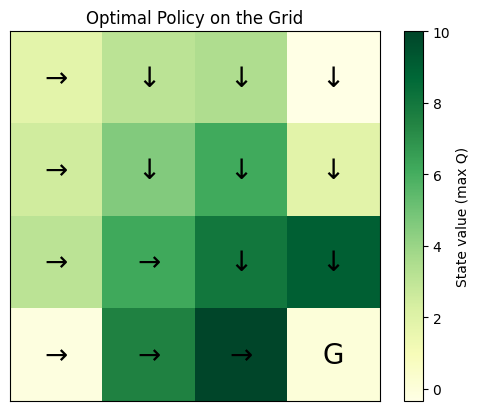

In [8]:
V = Q.max(axis=1).reshape(N, N)      # value of each state = best Q-value
V[N - 1, N - 1] = 0

plt.imshow(V, cmap="YlGn")
for s in range(N * N):
    r, c = divmod(s, N)
    plt.text(c, r, policy[s], ha="center", va="center", fontsize=20)
plt.colorbar(label="State value (max Q)")
plt.title("Optimal Policy on the Grid")
plt.xticks([])
plt.yticks([])
plt.show()

## Conclusion
- **ε = 0.5 (too much exploration):** half the moves are random, so the reward stays low and noisy (≈0.2 in the last 100 episodes).
- **ε = 0.1 and ε = 0.01 (mostly exploitation):** both learn the shortest path within ~60 episodes. ε = 0.01 gets the highest final reward (≈5.0) because it wastes almost no moves on random actions. ε = 0.1 is a bit lower (≈4.3) because 10% of its moves are still random.
- Exploration is still needed. Here it also comes from Q starting at 0 while every step gives −1, so untried actions look better than tried ones and the agent tries them anyway. In bigger worlds, too little exploration can miss the best path, which is why ε is often **decayed** (start high, end low).

The learned optimal policy reaches the goal in **6 steps**, the shortest possible path (3 down + 3 right), for a reward of 5 × (−1) + 10 = **5**.